In [1]:
import sys
sys.path.insert(0, "..")  # so "utils" (in the project root) can be imported from src/

from utils.modelling import *
from sklearn.tree import DecisionTreeClassifier

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
GAMMAS = [0, 0.25, 0.5, 0.75, 1.0]
weights = make_class_weights(ytrain)

def make_decision_tree_grid(model="A"):
    return GridSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            DecisionTreeClassifier(random_state=67)
        ),
        cv=5,
        param_grid={
            "decisiontreeclassifier__max_depth": [3, 5, 8, 12, None],
            "decisiontreeclassifier__min_samples_leaf": [1, 20, 100, 300],
            "decisiontreeclassifier__class_weight": [weights(g) for g in GAMMAS],
        },
        scoring="f1_macro",
        n_jobs=-1 # use all cores
    )

tree_grid_A = make_decision_tree_grid(model="A").fit(Xtrain, ytrain)
tree_model_tuned_A = tree_grid_A.best_estimator_
best_tree_params_A = tree_grid_A.best_params_
print(best_tree_params_A)
print(f"best CV macro F1: {tree_grid_A.best_score_:.4f}")

{'decisiontreeclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(2.5583787611427375), 2: np.float64(3.0085268107532097)}, 'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 20}
best CV macro F1: 0.4746


In [4]:
tree_val_A = evaluate_model(tree_model_tuned_A, Xval, yval, "Decision Tree A - VAL")

                 precision    recall  f1-score   support

           None       0.97      0.99      0.98     23976
          Minor       0.22      0.07      0.11       560
Subst/Destroyed       0.29      0.26      0.27       293

       accuracy                           0.96     24829
      macro avg       0.50      0.44      0.45     24829
   weighted avg       0.95      0.96      0.95     24829
 Model: Decision Tree A - VAL
F1 Macro: 0.4537
Balanced Accuracy: 0.4386
Accuracy: 0.9608
Recall: [0.99024024 0.06964286 0.2559727 ]
Confusion matrix (rows = true, columns = predicted):
[[23742   111   123]
 [  464    39    57]
 [  190    28    75]]


In [5]:
tree_grid_B = make_decision_tree_grid(model="B").fit(Xtrain, ytrain)
tree_model_tuned_B = tree_grid_B.best_estimator_
print(tree_grid_B.best_params_)

{'decisiontreeclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(2.5583787611427375), 2: np.float64(3.0085268107532097)}, 'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 20}


In [6]:
tree_val_B = evaluate_model(tree_model_tuned_B, Xval, yval, "Decision Tree B - VAL")

                 precision    recall  f1-score   support

           None       0.98      0.99      0.98     23976
          Minor       0.32      0.16      0.22       560
Subst/Destroyed       0.37      0.32      0.34       293

       accuracy                           0.96     24829
      macro avg       0.56      0.49      0.51     24829
   weighted avg       0.95      0.96      0.96     24829
 Model: Decision Tree B - VAL
F1 Macro: 0.5143
Balanced Accuracy: 0.4911
Accuracy: 0.9618
Recall: [0.98823824 0.16428571 0.32081911]
Confusion matrix (rows = true, columns = predicted):
[[23694   168   114]
 [  422    92    46]
 [  173    26    94]]


In [7]:
tree_cv = [cv_summary(tree_grid_A, "Decision Tree A"), cv_summary(tree_grid_B, "Decision Tree B")]

Decision Tree A: CV macro F1 = 0.4746 +/- 0.0173
Decision Tree B: CV macro F1 = 0.5251 +/- 0.0065


In [8]:
tree_test_A = evaluate_model(tree_model_tuned_A, Xtest, ytest, "Decision Tree A - TEST")

                 precision    recall  f1-score   support

           None       0.97      0.99      0.98     23976
          Minor       0.25      0.08      0.12       560
Subst/Destroyed       0.29      0.27      0.28       293

       accuracy                           0.96     24829
      macro avg       0.50      0.45      0.46     24829
   weighted avg       0.95      0.96      0.95     24829
 Model: Decision Tree A - TEST
F1 Macro: 0.4602
Balanced Accuracy: 0.4456
Accuracy: 0.9611
Recall: [0.99019853 0.08035714 0.2662116 ]
Confusion matrix (rows = true, columns = predicted):
[[23741   101   134]
 [  457    45    58]
 [  181    34    78]]


In [9]:
tree_test_B = evaluate_model(tree_model_tuned_B, Xtest, ytest, "Decision Tree B - TEST")

                 precision    recall  f1-score   support

           None       0.98      0.99      0.98     23976
          Minor       0.35      0.20      0.25       560
Subst/Destroyed       0.38      0.37      0.37       293

       accuracy                           0.96     24829
      macro avg       0.57      0.52      0.54     24829
   weighted avg       0.96      0.96      0.96     24829
 Model: Decision Tree B - TEST
F1 Macro: 0.5368
Balanced Accuracy: 0.5180
Accuracy: 0.9621
Recall: [0.98723724 0.19821429 0.36860068]
Confusion matrix (rows = true, columns = predicted):
[[23670   182   124]
 [  397   111    52]
 [  164    21   108]]


In [10]:
results = results_table([tree_val_A, tree_val_B, tree_test_A, tree_test_B])
results.to_csv("../results/decision_tree.csv", index=False)
pd.DataFrame(tree_cv).to_csv("../results/decision_tree_cv.csv", index=False)
results

,model,f1_macro,bal_acc,accuracy,precision_None,precision_Minor,precision_Subst/Destroyed,recall_None,recall_Minor,recall_Subst/Destroyed,f1_None,f1_Minor,f1_Subst/Destroyed
0,Decision Tree A - VAL,0.453685,0.438619,0.960812,0.973192,0.219101,0.294118,0.990240,0.069643,0.255973,0.981642,0.105691,0.273723
1,Decision Tree B - VAL,0.514339,0.491114,0.961779,0.975503,0.321678,0.370079,0.988238,0.164286,0.320819,0.981829,0.217494,0.343693
2,Decision Tree A - TEST,0.460218,0.445589,0.961134,0.973830,0.250000,0.288889,0.990199,0.080357,0.266212,0.981946,0.121622,0.277087
3,Decision Tree B - TEST,0.536790,0.518017,0.962141,0.976848,0.353503,0.380282,0.987237,0.198214,0.368601,0.982015,0.254005,0.374350


## plots

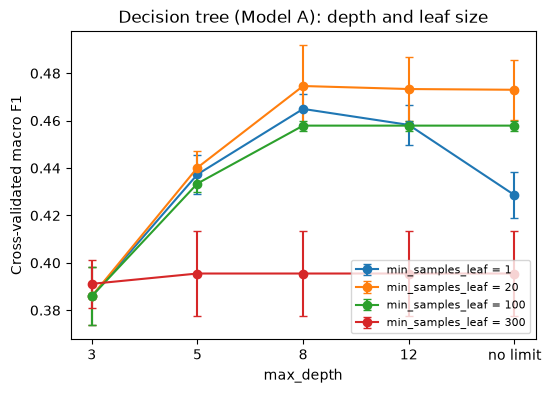

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

cv = pd.DataFrame(tree_grid_A.cv_results_)
best_weight = str(best_tree_params_A["decisiontreeclassifier__class_weight"])
cv = cv[cv["param_decisiontreeclassifier__class_weight"].map(str) == best_weight]
cv["depth"] = cv["param_decisiontreeclassifier__max_depth"].map(lambda d: "no limit" if d is None or pd.isna(d) else str(int(d)))

fig, ax = plt.subplots(figsize=(6, 4))
for leaf, group in cv.groupby("param_decisiontreeclassifier__min_samples_leaf"):
    ax.errorbar(group["depth"], group["mean_test_score"], yerr=group["std_test_score"], marker="o", capsize=3, label=f"min_samples_leaf = {leaf}")
ax.set_xlabel("max_depth")
ax.set_ylabel("Cross-validated macro F1")
ax.set_title("Decision tree (Model A): depth and leaf size")
ax.legend(loc="lower right", fontsize=8)
fig.savefig("../plots/tree_depth_leaf.png", dpi=200, bbox_inches="tight")

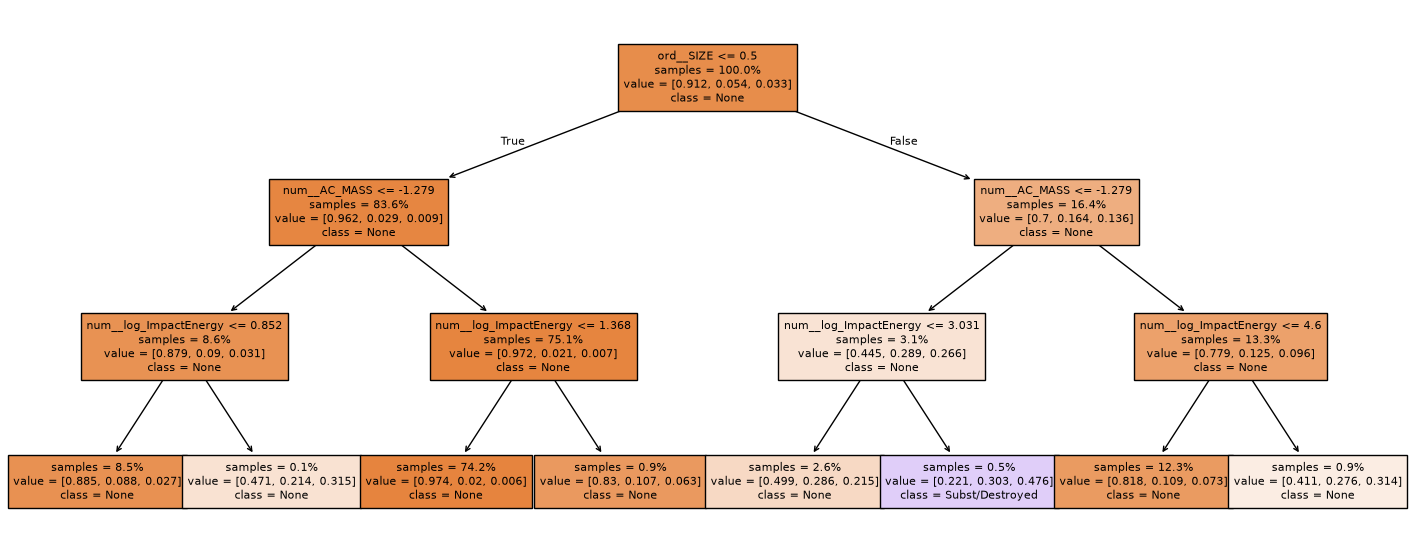

In [12]:
small_tree_A = make_pipeline(
    make_preprocessor(model="A"),
    DecisionTreeClassifier(max_depth=3, class_weight=best_tree_params_A["decisiontreeclassifier__class_weight"], random_state=67)
).fit(Xtrain, ytrain)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    small_tree_A.named_steps["decisiontreeclassifier"],
    feature_names=small_tree_A.named_steps["columntransformer"].get_feature_names_out(),
    class_names=LABELS,
    filled=True,
    impurity=False,
    proportion=True,
    fontsize=8,
    ax=ax,
)
fig.savefig("../plots/tree_depth3.png", dpi=200, bbox_inches="tight")

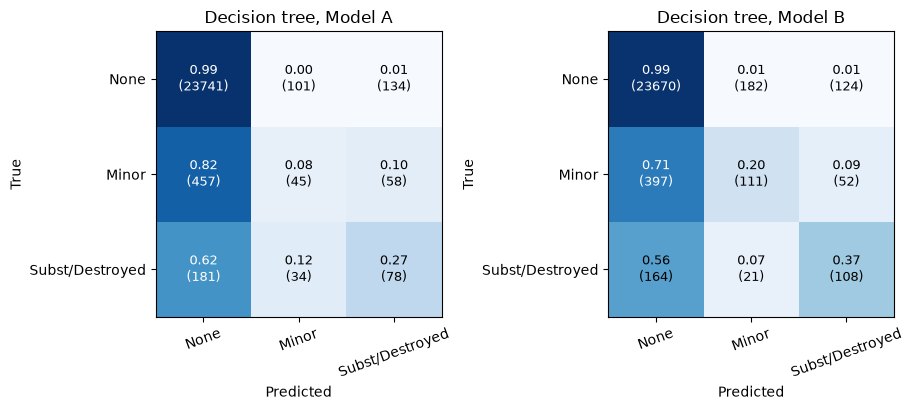

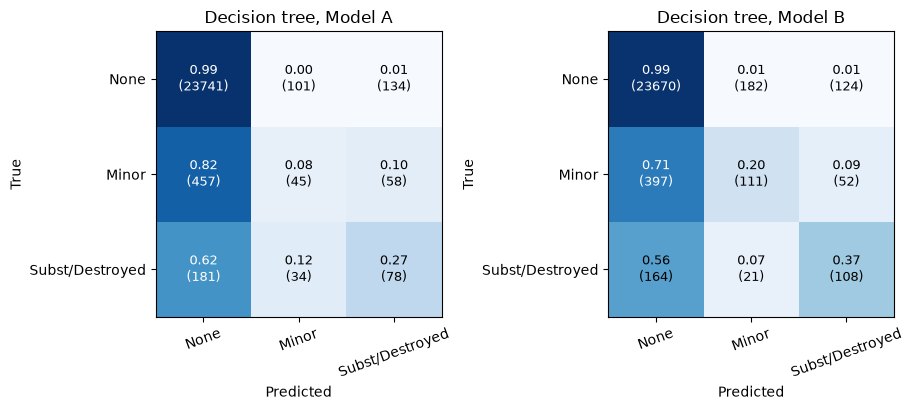

In [13]:
plot_confusion_matrices({"Decision tree, Model A": tree_model_tuned_A, "Decision tree, Model B": tree_model_tuned_B}, Xtest, ytest, "../plots/cm_decision_tree.png")